# Mock Interview Lab: Data & Analytics Lead, Google Cloud Consulting
Runnable companion to `ROUND_1_RRK_MOCK_10.md` and `ROUND_1_RRK_TOPIC_DEEP_DIVE.md`.
Everything runs **locally** (stdlib + pandas + matplotlib, no GCP account). Each section: **prompt, broken version, fix, tests**.

**How to use:** read the prompt, say your review aloud for the time given, then run the cells and compare.

| # | Section | Interview round | Time |
|---|---|---|---|
| 1 | Code review: buggy loader | RRK code review (Q15) | 8 min |
| 2 | Late, duplicate, out-of-order events | RRK technical (Q6) | 6 min |
| 3 | Write-Audit-Publish (atomic publication) | RRK technical | 5 min |
| 4 | Migration reconciliation | Architecture / migration | 5 min |
| 5 | SQL drill | Hands-on SQL | 6 min |
| 6 | FinOps cost model | Cost / consulting | 5 min |
| 7 | Score yourself | all | 3 min |

In [1]:
import sqlite3, hashlib, json, random
from decimal import Decimal, InvalidOperation
from collections import defaultdict
from datetime import datetime, timedelta, timezone
import pandas as pd
import matplotlib.pyplot as plt

# CP AXTRA palette (organisation standard)
BLUE, YELLOW, GREEN, RED = "#306FC7", "#F6C24A", "#43938F", "#DA3832"
print("sqlite", sqlite3.sqlite_version, "| pandas", pd.__version__)

sqlite 3.54.0 | pandas 3.0.5


## 1. Code review: what is wrong with this loader?
**Prompt (say your order aloud: correctness, idempotency, scale, semantics, security, maintainability):**
you are shown this function, written to load orders into a warehouse. List the defects before running anything.

In [2]:
RATES = {"USD": Decimal("1"), "SGD": Decimal("0.74"), "THB": Decimal("0.028")}
class FakeWarehouse:
    """Stand-in for a streaming insert API: append-only, no dedup, returns per-row errors."""
    def __init__(self): self.rows = []
    def insert_rows_json(self, rows):
        errors = []
        for r in rows:
            if r.get("amount_usd") is None: errors.append({"row": r, "error": "null amount"})
            else: self.rows.append(dict(r))
        return errors

def load_orders_buggy(rows, wh):
    seen, out = set(), []
    for r in rows:
        if r["order_id"] in seen:          # first-seen wins, ignores version
            continue
        seen.add(r["order_id"])
        r["amount_usd"] = float(r["amount"]) * float(RATES[r["currency"]])   # float money, KeyError risk
        r["order_date"] = r["ts"][:10]                                       # assumes UTC
        out.append(r)
    wh.insert_rows_json(out)                                                  # errors ignored
    print("loaded", len(out), out[:2])                                        # PII in logs
    return len(out)

batch = [
    {"order_id": "A1", "version": 1, "amount": "100.10", "currency": "SGD", "ts": "2026-01-02T01:30:00+08:00"},
    {"order_id": "A1", "version": 2, "amount": "120.00", "currency": "SGD", "ts": "2026-01-02T01:35:00+08:00"},  # newer, same order
    {"order_id": "B2", "version": 1, "amount": "50", "currency": "XXX", "ts": "2026-01-02T01:00:00Z"},           # unknown currency
]
wh = FakeWarehouse()
try:
    load_orders_buggy([dict(r) for r in batch], wh)
except KeyError as e:
    print("BUG 1: KeyError on unknown currency ->", e, "(whole batch lost)")

good_only = [dict(r) for r in batch[:2]]
load_orders_buggy(good_only, wh)
print("BUG 2: kept version", wh.rows[0]["version"], "instead of 2 (first-seen wins)")
load_orders_buggy([dict(r) for r in batch[:2]], wh)   # simulated retry after a timeout
print("BUG 3: rows after a retry =", len(wh.rows), "(re-run duplicates everything)")
print("BUG 4: order_date =", wh.rows[0]["order_date"], "(01:30 +08:00 on Jan 2 is Jan 1 in UTC; naive slicing gives the wrong date)")

BUG 1: KeyError on unknown currency -> 'XXX' (whole batch lost)
loaded 1 [{'order_id': 'A1', 'version': 1, 'amount': '100.10', 'currency': 'SGD', 'ts': '2026-01-02T01:30:00+08:00', 'amount_usd': 74.074, 'order_date': '2026-01-02'}]
BUG 2: kept version 1 instead of 2 (first-seen wins)
loaded 1 [{'order_id': 'A1', 'version': 1, 'amount': '100.10', 'currency': 'SGD', 'ts': '2026-01-02T01:30:00+08:00', 'amount_usd': 74.074, 'order_date': '2026-01-02'}]
BUG 3: rows after a retry = 2 (re-run duplicates everything)
BUG 4: order_date = 2026-01-02 (01:30 +08:00 on Jan 2 is Jan 1 in UTC; naive slicing gives the wrong date)


**Findings to say aloud (rank the first two highest):** (1) retry duplicates, no idempotent key; (2) dropped or failed rows are silent, no dead-letter; (3) first-seen wins ignores version; (4) one bad currency kills the whole batch; (5) float money; (6) timezone-naive date slicing; (7) PII in logs; (8) mutates caller's input; (9) unbounded memory, no batching; (10) no tests.

In [3]:
class Sink:
    """Idempotent upsert keyed by order_id with a version guard (stands in for MERGE)."""
    def __init__(self):
        self.db = sqlite3.connect(":memory:")
        self.db.execute("create table orders(order_id text primary key, version int, amount_usd text, order_date text)")
        self.db.execute("create table dead_letter(raw text, reason text)")
    def upsert(self, rec):
        self.db.execute('''insert into orders values(:order_id,:version,:amount_usd,:order_date)
            on conflict(order_id) do update set version=excluded.version, amount_usd=excluded.amount_usd,
            order_date=excluded.order_date where excluded.version > orders.version''', rec)
    def dead(self, raw, reason):
        self.db.execute("insert into dead_letter values(?,?)", (json.dumps(raw), reason))
    def orders(self): return {r[0]: r[1:] for r in self.db.execute("select * from orders")}
    def dlq(self): return list(self.db.execute("select reason from dead_letter"))

def transform(r):
    """Pure, no mutation of input; raises ValueError with a reason on bad data."""
    try:
        amt = Decimal(r["amount"])
    except (InvalidOperation, KeyError, TypeError):
        raise ValueError("bad amount")
    if amt < 0: raise ValueError("negative amount")
    rate = RATES.get(r.get("currency"))
    if rate is None: raise ValueError(f"unknown currency {r.get('currency')}")
    ts = datetime.fromisoformat(r["ts"].replace("Z", "+00:00"))
    if ts.tzinfo is None: raise ValueError("naive timestamp")
    return {"order_id": r["order_id"], "version": int(r["version"]),
            "amount_usd": str((amt * rate).quantize(Decimal("0.01"))),
            "order_date": ts.astimezone(timezone.utc).date().isoformat()}

def load_orders(rows, sink, chunk=1000):
    ok = bad = 0
    for i in range(0, len(rows), chunk):               # bounded batches
        for r in rows[i:i+chunk]:
            try: sink.upsert(transform(r)); ok += 1
            except ValueError as e: sink.dead(r, str(e)); bad += 1   # auditable, not silent
        sink.db.commit()
    return ok, bad

s = Sink()
print(load_orders([dict(r) for r in batch], s))
first = s.orders()
print(load_orders([dict(r) for r in batch], s))        # retry
assert s.orders() == first, "idempotency broken"
assert s.orders()["A1"][0] == 2, "newest version must win"
assert s.orders()["A1"][2] == "2026-01-01", "UTC date: 01:35+08:00 on Jan 2 is 17:35Z on Jan 1"
assert s.dlq() == [("unknown currency XXX",), ("unknown currency XXX",)]
# out-of-order: older version arriving late must not overwrite newer
load_orders([{"order_id": "A1", "version": 1, "amount": "1", "currency": "USD", "ts": "2026-01-01T00:00:00Z"}], s)
assert s.orders()["A1"][0] == 2
print("all review fixes verified:", s.orders())

(2, 1)
(2, 1)
all review fixes verified: {'A1': (2, '88.80', '2026-01-01')}


## 2. Late, duplicate and out-of-order events
**Prompt:** 10B rows/day, duplicates and late events corrupt aggregates. Show event-time windows with a watermark, allowed lateness and a dead-letter side output.
Say what the watermark is (the system's estimate of event-time completeness), and how you choose lateness from the measured p99.

In [4]:
def window_start(ts, size=60): return ts - (ts % size)

def process(events, size=60, allowed_lateness=120, watermark_delay=30):
    """Tumbling event-time windows; dedupe on event_id; watermark = max_event_time - delay.
    A window may still be updated until watermark < window_end + allowed_lateness; after that -> dead letter."""
    seen, windows, dead = set(), defaultdict(int), []
    max_ts = 0; dup = 0
    for e in events:                                    # events arrive in ARRIVAL order
        if e["event_id"] in seen: dup += 1; continue
        seen.add(e["event_id"])
        max_ts = max(max_ts, e["ts"])
        watermark = max_ts - watermark_delay
        w = window_start(e["ts"], size)
        if watermark >= w + size + allowed_lateness:    # too late: window is finalized
            dead.append(e); continue
        windows[w] += 1
    return dict(sorted(windows.items())), dead, dup

random.seed(7)
base = [{"event_id": f"e{i}", "ts": i * 5} for i in range(60)]          # 60 events over 300s
arrival = base[:]
random.shuffle(arrival[:50])                                              # mild disorder
arrival = arrival + [dict(base[3]), dict(base[10])]                      # producer retries (duplicates)
arrival.append({"event_id": "late1", "ts": 12})                          # arrives after clock passed 300s
windows, dead, dup = process(arrival)
print("windows:", windows); print("dead-letter:", [d["event_id"] for d in dead]); print("duplicates dropped:", dup)
assert dup == 2 and [d["event_id"] for d in dead] == ["late1"]
assert sum(windows.values()) == 60, "each unique on-time event counted exactly once"
# larger lateness would have admitted the late event: the policy choice has a cost (state held longer)
w2, d2, _ = process(arrival, allowed_lateness=400)
assert d2 == [] and sum(w2.values()) == 61
print("trade-off shown: more lateness = fewer drops, more state and later finalization")

windows: {0: 12, 60: 12, 120: 12, 180: 12, 240: 12}
dead-letter: ['late1']
duplicates dropped: 2
trade-off shown: more lateness = fewer drops, more state and later finalization


**Say aloud:** end-to-end exactly-once needs an idempotent sink; dedup on a producer-assigned ID, not on the transport's message ID; route too-late events to a side output and reconcile in a batch correction.

## 3. Write-Audit-Publish (atomic publication)
**Prompt:** consumers must never see half a load, and a failed validation must leave yesterday's data live.

In [5]:
def wap(db, staged_rows, audits):
    db.execute("drop table if exists stg")
    db.execute("create table stg(k text primary key, v real)")
    db.executemany("insert into stg values(?,?)", staged_rows)                  # WRITE
    failures = [name for name, sql in audits.items() if db.execute(sql).fetchone()[0]]   # AUDIT
    if failures:
        return False, failures                                                    # prod untouched
    with db:                                                                      # PUBLISH atomically
        db.execute("drop table if exists prod_new")
        db.execute("create table prod_new as select * from stg")
        db.execute("drop table if exists prod"); db.execute("alter table prod_new rename to prod")
    return True, []

db = sqlite3.connect(":memory:")
db.execute("create table prod(k text primary key, v real)"); db.execute("insert into prod values('old',1)")
audits = {"null_values": "select count(*) from stg where v is null",
          "negative": "select count(*) from stg where v < 0",
          "too_few_rows": "select case when count(*) < 2 then 1 else 0 end from stg"}
ok, f = wap(db, [("a", 1.0), ("b", None)], audits)
print("bad load ->", ok, f, "| prod:", db.execute("select * from prod").fetchall())
assert not ok and db.execute("select k from prod").fetchall() == [("old",)]
ok, f = wap(db, [("a", 1.0), ("b", 2.0)], audits)
print("good load ->", ok, "| prod:", db.execute("select * from prod order by k").fetchall())
assert ok and db.execute("select count(*) from prod").fetchone()[0] == 2

bad load -> False ['null_values'] | prod: [('old', 1.0)]
good load -> True | prod: [('a', 1.0), ('b', 2.0)]


## 4. Migration reconciliation (prove the new warehouse is correct)
**Prompt:** after migrating a table, show row counts, per-column checksums, and a row-level diff.

In [6]:
random.seed(3)
src = pd.DataFrame({"id": range(1, 1001), "amount": [round(random.uniform(1, 500), 2) for _ in range(1000)],
                    "region": [random.choice(["SG", "TH", "VN"]) for _ in range(1000)]})
tgt = src.copy()
tgt = tgt[tgt.id != 500]                                  # missing row
tgt.loc[tgt.id == 10, "amount"] += 0.05                   # silent value drift
tgt.loc[tgt.id == 20, "region"] = "sg"                    # case-handling difference
tgt = pd.concat([tgt, tgt[tgt.id == 30]])                 # duplicated row

def col_checksum(df, c):
    return hashlib.md5("|".join(map(str, sorted(df[c].astype(str)))).encode()).hexdigest()[:8]

def reconcile(src, tgt, key="id"):
    rep = {"row_count": (len(src), len(tgt)),
           "dup_keys_target": int(tgt[key].duplicated().sum()),
           "missing_in_target": sorted(set(src[key]) - set(tgt[key])),
           "extra_in_target": sorted(set(tgt[key]) - set(src[key])),
           "sum_amount": (round(src.amount.sum(), 2), round(tgt.amount.sum(), 2)),
           "checksums": {c: (col_checksum(src, c), col_checksum(tgt, c)) for c in src.columns}}
    m = src.merge(tgt.drop_duplicates(key), on=key, suffixes=("_s", "_t"))
    diffs = m[(m.amount_s != m.amount_t) | (m.region_s != m.region_t)][[key]].id.tolist()
    rep["value_diffs"] = diffs
    rep["pass"] = (rep["row_count"][0] == rep["row_count"][1] and not rep["dup_keys_target"] and not diffs
                   and not rep["missing_in_target"])
    return rep
r = reconcile(src, tgt)
print(json.dumps(r, indent=1, default=str))
assert r["missing_in_target"] == [500] and r["value_diffs"] == [10, 20] and r["dup_keys_target"] == 1 and not r["pass"]
assert reconcile(src, src.copy())["pass"]
print("reconciliation catches: missing row, duplicate, value drift, case change")

{
 "row_count": [
  1000,
  1000
 ],
 "dup_keys_target": 1,
 "missing_in_target": [
  500
 ],
 "extra_in_target": [],
 "sum_amount": [
  248773.86,
  248849.52
 ],
 "checksums": {
  "id": [
   "8a7950a3",
   "8c7f4c11"
  ],
  "amount": [
   "52b613ea",
   "e7197f00"
  ],
  "region": [
   "68f5c9de",
   "7cc05fe2"
  ]
 },
 "value_diffs": [
  10,
  20
 ],
 "pass": false
}
reconciliation catches: missing row, duplicate, value drift, case change


**Say aloud:** counts alone passed here by coincidence (one row lost, one duplicated). That is why you also need key-level diffs, checksums and a business-KPI parity run across a month-end.

## 5. SQL drill (window functions)
**Prompt:** (a) latest record per key, (b) sessionise events with a 30-minute gap, (c) top-2 products per region. Write each query before running.

In [7]:
con = sqlite3.connect(":memory:")
con.executescript('''
create table cust(id int, name text, updated_at text);
insert into cust values (1,'old','2026-01-01'),(1,'new','2026-02-01'),(2,'only','2026-01-15');
create table ev(user text, t text);
insert into ev values ('u1','2026-01-01 10:00'),('u1','2026-01-01 10:10'),('u1','2026-01-01 11:00'),('u2','2026-01-01 09:00');
create table sales(region text, product text, amt real);
insert into sales values ('SG','a',10),('SG','b',30),('SG','c',20),('TH','a',5),('TH','b',7);
''')
q = lambda s: pd.read_sql(s, con)
latest = q("select id, name from (select *, row_number() over(partition by id order by updated_at desc) rn from cust) where rn=1")
sess = q('''select user, t, sum(new_s) over(partition by user order by t) as session_no from (
              select user, t, case when lag(t) over(partition by user order by t) is null
                   or (julianday(t) - julianday(lag(t) over(partition by user order by t))) * 1440 > 30 then 1 else 0 end new_s
              from ev)''')
top2 = q("select region, product, amt from (select *, row_number() over(partition by region order by amt desc) rn from sales) where rn<=2 order by region, amt desc")
print(latest, sess, top2, sep="\n\n")
assert latest.set_index("id").name.to_dict() == {1: "new", 2: "only"}
assert sess[sess.user == "u1"].session_no.tolist() == [1, 1, 2]
assert top2[top2.region == "SG"]["product"].tolist() == ["b", "c"]
print("BigQuery equivalents: QUALIFY ROW_NUMBER() ... = 1; TIMESTAMP_DIFF; same window logic.")

   id  name
0   1   new
1   2  only

  user                 t  session_no
0   u1  2026-01-01 10:00           1
1   u1  2026-01-01 10:10           1
2   u1  2026-01-01 11:00           2
3   u2  2026-01-01 09:00           1

  region product   amt
0     SG       b  30.0
1     SG       c  20.0
2     TH       b   7.0
3     TH       a   5.0
BigQuery equivalents: QUALIFY ROW_NUMBER() ... = 1; TIMESTAMP_DIFF; same window logic.


## 6. FinOps cost model: on-demand versus reservations
**Prompt:** a client's spend is rising. Compare on-demand with a reserved-capacity model from their usage. **The rates below are placeholders to show the method; replace them with current list prices before quoting any number.**

on-demand $14,127 | reserved baseline $21,600 | delta +52.9%
Verdict with these inputs: on-demand is cheaper (baseline too high for this usage)
Lesson: reservations pay off only when steady utilisation is high. Model from real slot-usage history, size the baseline to the steady floor, autoscale for peaks, separate ETL / BI / ad hoc; never promise a % before the model.


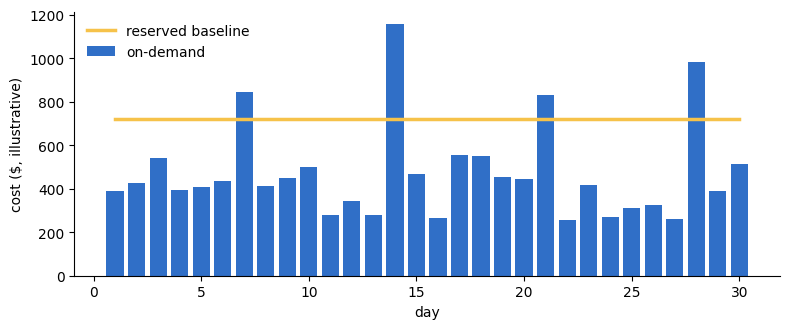

guardrail demo: BLOCKED by maximum_bytes_billed / ok


In [8]:
ON_DEMAND_PER_TB = 6.25          # PLACEHOLDER, check current pricing
SLOT_HOUR = 0.06                 # PLACEHOLDER, check current pricing
random.seed(11)
days = list(range(1, 31))
tb_scanned = [round(random.uniform(40, 90), 1) if d % 7 else round(random.uniform(120, 200), 1) for d in days]
on_demand = [t * ON_DEMAND_PER_TB for t in tb_scanned]
baseline_slots, hours = 500, 24
reserved_flat = baseline_slots * SLOT_HOUR * hours                        # steady baseline per day
reserved = [reserved_flat for _ in days]
df = pd.DataFrame({"day": days, "tb": tb_scanned, "on_demand": on_demand, "reserved": reserved})
tot_od, tot_rs = df.on_demand.sum(), df.reserved.sum()
print(f"on-demand ${tot_od:,.0f} | reserved baseline ${tot_rs:,.0f} | delta {100*(tot_rs-tot_od)/tot_od:+.1f}%")
print("Verdict with these inputs:", "reservation is cheaper" if tot_rs < tot_od else "on-demand is cheaper (baseline too high for this usage)")
print("Lesson: reservations pay off only when steady utilisation is high. Model from real slot-usage history,",
      "size the baseline to the steady floor, autoscale for peaks, separate ETL / BI / ad hoc; never promise a % before the model.")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(df.day, df.on_demand, color=BLUE, label="on-demand"); ax.plot(df.day, df.reserved, color=YELLOW, lw=2.5, label="reserved baseline")
ax.set_xlabel("day"); ax.set_ylabel("cost ($, illustrative)"); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
guard = lambda tb: "BLOCKED by maximum_bytes_billed" if tb > 150 else "ok"
print("guardrail demo:", guard(200), "/", guard(60))

## 7. Score yourself
Score each mock answer 0 to 2 on four lines (max 8 per answer). Targets: 60 of 80 across ten answers = ready.

In [9]:
RUBRIC = ["structure", "judgement", "evidence_numbers", "enterprise_scope"]
def score(**kw):
    bad = [k for k in kw if k not in RUBRIC or kw[k] not in (0, 1, 2)]
    assert not bad, f"use {RUBRIC} with 0/1/2: {bad}"
    return sum(kw.values())
# example: replace with your own after each answer
log = {"Q1 background": score(structure=2, judgement=1, evidence_numbers=1, enterprise_scope=2)}
print(log, "total", sum(log.values()), "/ 8 per answer")

{'Q1 background': 6} total 6 / 8 per answer


### Final checklist before the interview
- Say the GCP-gap statement and the dated 60-day plan aloud.
- Fill the 8 `[TODO]`s and the `[YOUR ...]` story slots with true facts.
- Re-run every cell above and explain each assertion without looking.
- Do one live mock where someone interrupts with "why?".